# 07 – Forecasting (EVISION 360)

**ප්‍රශ්නය:** රටවල් වල EV share (නව car sales වල EV ප්‍රතිශතය) ඉදිරි අවුරුදු 3 තුළ (2026–2028) වෙනස් වෙන්නේ කොහොමද? ඒ අනුමාන කොච්චර විශ්වාස කරන්න පුළුවන්ද?

Phase 06 එකෙන් ඉගෙන ගත්ත දේ: structural ML models "වෙනසක් නැහැ" (persistence) baseline එකට වඩා නරක. ඒ නිසා මේ notebook එකේ **ඕනෑම forecast method එකක් මුලින් backtest කරනවා**, සහ persistence ට වඩා හොඳද කියලා statistically පරීක්ෂා කරනවා.

| Section | කරන දේ |
| --- | --- |
| 1 | Methods සහ backtest සැලසුම (rolling origin, selection period + holdout) |
| 2 | Backtest ප්‍රතිඵල |
| 3 | Method තෝරන ක්‍රමය + persistence සමඟ සංඛ්‍යාත්මක සසඳීම (bootstrap CI) |
| 4 | අවිනිශ්චිතතාව: error ප්‍රමාණය සහ interval coverage පරීක්ෂාව |
| 5 | Forecasts 2026–2028 |
| 6 | IEA 2035 scenarios සමඟ සසඳීම (extrapolation නැතුව) |
| 7 | Findings |

**Horizon එක අවුරුදු 3කට සීමා කරනවා** (backtest කරන්න පුළුවන් උපරිමය). IEA STEPS/CPS කියන්නේ scenarios මිස forecasts නෙවෙයි.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sqlalchemy import text

warnings.filterwarnings("ignore")
ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT / "src/ingestion"))
from db import get_engine

engine = get_engine()
FIG = ROOT / "reports/figures"; FIG.mkdir(parents=True, exist_ok=True)
OUT = ROOT / "data/processed"; OUT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
SEED = 42

BG, PANEL, TXT, GRID = "#0b1426", "#0f1d36", "#e6f1ff", "#22345a"
CYAN, GREEN, AMBER, PINK, GREY = "#00e5ff", "#39ff88", "#ffb347", "#ff5ea8", "#8fa3c7"
plt.rcParams.update({
    "figure.facecolor": BG, "axes.facecolor": PANEL, "savefig.facecolor": BG, "text.color": TXT,
    "axes.labelcolor": TXT, "axes.edgecolor": GRID, "xtick.color": TXT, "ytick.color": TXT,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.alpha": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10, "axes.titlesize": 11,
    "axes.titleweight": "bold", "legend.facecolor": PANEL, "legend.edgecolor": GRID,
})


def q(sql, params=None):
    with engine.connect() as conn:
        conn.exec_driver_sql("SET search_path TO evision")
        return pd.read_sql(text(sql), conn, params=params)


def save(fig, name):
    fig.savefig(FIG / name, dpi=150, bbox_inches="tight"); print("saved", name)


# IEA EV share of new car sales (cars, all geographies) and 2025 EV car sales volume
shares = q("""
    SELECT g.geo_code, g.geo_name, g.geo_type, s.scenario_code AS scenario, f.year, f.value
    FROM fact_ev_market_annual f JOIN dim_geography g USING (geo_key) JOIN dim_indicator i USING (indicator_key)
    JOIN dim_scenario s USING (scenario_key)
    WHERE i.parameter_code = 'ev_sales_share' AND i.vehicle_mode = 'Cars' AND i.powertrain = 'EV' AND NOT f.is_suspect_value""")
volume25 = q("""
    SELECT g.geo_code, f.value AS ev_sales_2025
    FROM fact_ev_market_annual f JOIN dim_geography g USING (geo_key) JOIN dim_indicator i USING (indicator_key)
    JOIN dim_scenario s USING (scenario_key)
    WHERE i.parameter_code = 'ev_sales' AND i.vehicle_mode = 'Cars' AND i.powertrain = 'EV'
      AND s.scenario_code = 'Historical' AND f.year = 2025 AND g.geo_type = 'country'""")
names = shares.drop_duplicates("geo_code").set_index("geo_code")["geo_name"]
hist = shares[(shares["scenario"] == "Historical")]
S = hist[hist["geo_type"] == "country"].pivot(index="year", columns="geo_code", values="value").clip(lower=0.01, upper=99.9)
LAST = int(S.index.max())
print(f"Countries: {S.shape[1]} | years {int(S.index.min())}-{LAST} | observed shares in {LAST}: {int(S.loc[LAST].notna().sum())}")

Countries: 61 | years 2010-2025 | observed shares in 2025: 60


## 1. Methods සහ backtest සැලසුම

**Methods (සරල ඒවා, රටවල් 60ක data වලට ගැලපෙන):**

| Method | විස්තරය |
| --- | --- |
| `persistence` | අන්තිම share එකම ඉදිරියටත් ("වෙනසක් නැහැ") |
| `drift3` | අන්තිම අවුරුදු 3ේ සාමාන්‍ය වාර්ෂික වෙනස (pp) ඉදිරියට රේඛීයව දිගු කිරීම |
| `drift3_damped` | drift3 ම, ඒත් වෙනස හැම අවුරුද්දකම 0.8× බැගින් අඩු වෙනවා (වර්ධනය මන්දගාමී වෙනවා) |
| `logit_damped` | අන්තිම අවුරුදු 4ේ logit(share) රේඛාව, damped (S-curve ස්වභාවයක්) |

**Backtest (rolling origin):** origin T = 2018…2023, horizon h = 1,2,3. හැම origin එකකදීම T දක්වා data පමණක් භාවිතා කරලා T+h අනුමාන කරනවා, සැබෑ අගය එක්ක සසඳනවා.

- **Selection period:** origins 2018–2021 (method එක තෝරන්නේ මේකෙන් පමණයි)
- **Holdout:** origins 2022–2023 (තෝරාගත් method එක පරීක්ෂා කරන්නේ මේකෙන්, තෝරන්න පාවිච්චි කරන්නේ නැහැ)

**අවංක සටහන:** Methods 4 තෝරාගත්තේ පළමු backtest එක බැලූ පසු `drift3_damped` එකතු කරලා (logit methods over-forecast කරන බව දැක්කාට පස්සේ). Parameters (අවුරුදු 3 window, 0.8 damping) holdout එක බලලා tune කළේ නැහැ.

In [2]:
PHI = 0.8
METHODS = ["persistence", "drift3", "drift3_damped", "logit_damped"]
sigmoid = lambda z: 100 / (1 + np.exp(-z))


def forecast(series, origin, h, method):
    """Forecast `series` (indexed by year) h years ahead using data up to `origin` only."""
    s = series.loc[:origin].dropna()
    if len(s) < 5 or s.index[-1] != origin:
        return np.nan
    last = s.iloc[-1]
    if method == "persistence":
        return last
    if method in ("drift3", "drift3_damped"):
        if origin - 3 not in s.index:
            return np.nan
        slope = (last - s.loc[origin - 3]) / 3
        steps = h if method == "drift3" else sum(PHI ** j for j in range(1, h + 1))
        return float(np.clip(last + steps * slope, 0, 100))
    if method == "logit_damped":
        y = np.log(s.iloc[-4:].values / 100 / (1 - s.iloc[-4:].values / 100))
        slope = np.polyfit(np.arange(4), y, 1)[0]
        return sigmoid(y[-1] + slope * sum(PHI ** j for j in range(1, h + 1)))
    raise ValueError(method)


rows = []
for origin in range(2018, 2024):
    for h in (1, 2, 3):
        if origin + h > LAST:
            continue
        for geo in S.columns:
            actual = S.loc[origin + h, geo]
            if pd.isna(actual):
                continue
            preds = {m: forecast(S[geo], origin, h, m) for m in METHODS}
            if any(np.isnan(v) for v in preds.values()):
                continue   # every method is scored on exactly the same forecasts
            rows.append({"origin": origin, "h": h, "geo": geo, "last": S.loc[origin, geo], "actual": actual, **preds})
bt = pd.DataFrame(rows)
bt["period"] = np.where(bt["origin"] <= 2021, "selection", "holdout")
bt["band"] = pd.cut(bt["last"], [0, 5, 20, 100], labels=["<5%", "5-20%", ">=20%"], right=False).astype(str)
print(f"Backtest forecasts per method: selection {int((bt['period'] == 'selection').sum())}, holdout {int((bt['period'] == 'holdout').sum())} "
      f"(origins 2018-2023, horizons 1-3, {bt['geo'].nunique()} countries)")

Backtest forecasts per method: selection 541, holdout 260 (origins 2018-2023, horizons 1-3, 55 countries)


## 2. Backtest ප්‍රතිඵල

--- selection period: MAE (pp) ---
method  persistence  drift3  drift3_damped  logit_damped
h                                                       
1              3.28    2.41           2.44          2.65
2              7.02    5.13           5.37          5.51
3             10.18    7.73           8.10          8.76
--- holdout period: MAE (pp) ---
method  persistence  drift3  drift3_damped  logit_damped
h                                                       
1              3.52    3.51           3.26          4.34
2              6.09    6.14           5.36          8.30
3              9.37    7.62           6.92         12.28
--- holdout: RMSE (pp) ---
method  persistence  drift3  drift3_damped  logit_damped
h                                                       
1              5.39    6.00           5.55          6.62
2              8.15    9.93           8.46         11.49
3             11.73   11.79          10.07         15.72
--- holdout: bias = forecast - actual (pp; negativ

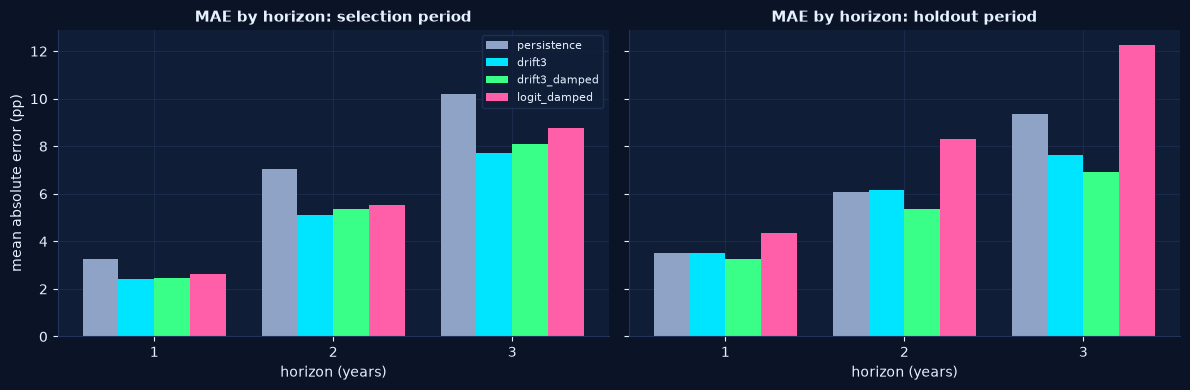

In [3]:
def error_table(d):
    out = []
    for h, g in d.groupby("h"):
        for m in METHODS:
            e = g[m] - g["actual"]
            out.append({"h": h, "method": m, "MAE": e.abs().mean(), "RMSE": np.sqrt((e ** 2).mean()), "bias": e.mean(), "n": len(g)})
    return pd.DataFrame(out)


tabs = {p: error_table(bt[bt["period"] == p]) for p in ("selection", "holdout")}
for p, t in tabs.items():
    print(f"--- {p} period: MAE (pp) ---"); print(t.pivot(index="h", columns="method", values="MAE")[METHODS].round(2).to_string())
print("--- holdout: RMSE (pp) ---"); print(tabs["holdout"].pivot(index="h", columns="method", values="RMSE")[METHODS].round(2).to_string())
print("--- holdout: bias = forecast - actual (pp; negative = under-forecast) ---")
print(tabs["holdout"].pivot(index="h", columns="method", values="bias")[METHODS].round(2).to_string())

colors = {"persistence": GREY, "drift3": CYAN, "drift3_damped": GREEN, "logit_damped": PINK}
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (p, t) in zip(axes, tabs.items()):
    piv = t.pivot(index="h", columns="method", values="MAE")[METHODS]
    for k, m in enumerate(METHODS):
        ax.bar(piv.index + (k - 1.5) * 0.2, piv[m], width=0.2, color=colors[m], label=m)
    ax.set(title=f"MAE by horizon: {p} period", xlabel="horizon (years)", xticks=[1, 2, 3])
axes[0].set_ylabel("mean absolute error (pp)"); axes[0].legend(fontsize=8)
plt.tight_layout(); save(fig, "19_forecast_backtest_mae.png"); plt.show()

## 3. Method තෝරන ක්‍රමය + persistence සමඟ සංඛ්‍යාත්මක සසඳීම

**Selection rule (ඉහත සැලසුමට අනුව, holdout බලන්නේ නැතුව):** selection period එකේ horizons 3ටම සාමාන්‍ය MAE එක අඩුම method එක.

ඊට පස්සේ **holdout** එකේ ඒ method එක persistence ට වඩා හොඳද? Country එකක් කිහිප origins වල ඇතුළත් වෙන නිසා observations ස්වාධීන නෑ. ඒ නිසා **country-cluster bootstrap** (රටවල් නැවත sample කරලා) මගින් MAE වෙනසේ 95% CI එක ගන්නවා. CI එක 0 ඇතුළත් නම් වෙනස "සනාථ වෙලා නැහැ".

Mean selection-period MAE across horizons:
method
drift3           5.09
drift3_damped    5.31
logit_damped     5.64
persistence      6.83

Selected method (rule above): drift3
Holdout: MAE(drift3) - MAE(persistence), country-cluster bootstrap (negative = drift3 better):
 h  n_forecasts  countries  MAE_diff_pp  ci_low  ci_high  distinguishable_from_zero
 1          105         55        -0.01   -0.73     0.75                      False
 2          104         54         0.05   -1.55     1.75                      False
 3           51         51        -1.75   -4.63     1.25                      False
saved 20_forecast_vs_persistence_ci.png


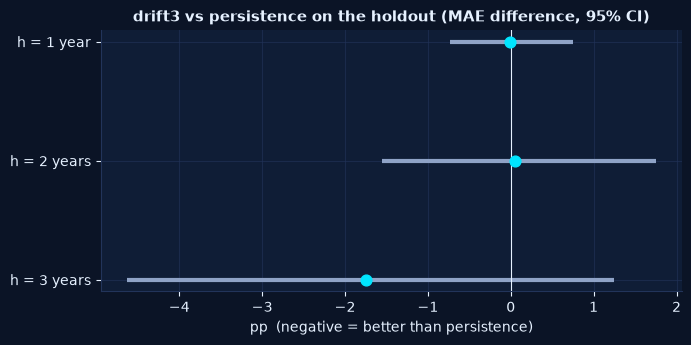

In [4]:
sel_mae = tabs["selection"].groupby("method")["MAE"].mean().sort_values()
SELECTED = sel_mae.index[0]
print("Mean selection-period MAE across horizons:"); print(sel_mae.round(2).to_string())
print(f"\nSelected method (rule above): {SELECTED}")

compare = SELECTED if SELECTED != "persistence" else "drift3"
hold = bt[bt["period"] == "holdout"].copy()
hold["diff"] = (hold[compare] - hold["actual"]).abs() - (hold["persistence"] - hold["actual"]).abs()   # negative = better than persistence
rng = np.random.default_rng(SEED)
rows = []
for h, d in hold.groupby("h"):
    by_geo = d.groupby("geo")["diff"].agg(["sum", "count"])
    boots = []
    for _ in range(3000):
        pick = rng.choice(by_geo.index.values, len(by_geo))
        boots.append(by_geo.loc[pick, "sum"].sum() / by_geo.loc[pick, "count"].sum())
    rows.append({"h": h, "n_forecasts": len(d), "countries": d["geo"].nunique(), "MAE_diff_pp": d["diff"].mean(),
                 "ci_low": np.percentile(boots, 2.5), "ci_high": np.percentile(boots, 97.5)})
ci = pd.DataFrame(rows)
ci["distinguishable_from_zero"] = (ci["ci_low"] > 0) | (ci["ci_high"] < 0)
print(f"Holdout: MAE({compare}) - MAE(persistence), country-cluster bootstrap (negative = {compare} better):")
print(ci.round(2).to_string(index=False))

fig, ax = plt.subplots(figsize=(7.5, 3.4))
yy = np.arange(len(ci))[::-1]
ax.hlines(yy, ci["ci_low"], ci["ci_high"], color=GREY, lw=3)
ax.scatter(ci["MAE_diff_pp"], yy, color=CYAN, s=60, zorder=3); ax.axvline(0, color=TXT, lw=0.8)
ax.set_yticks(yy); ax.set_yticklabels([f"h = {h} year" + ("s" if h > 1 else "") for h in ci["h"]])
ax.set(title=f"{compare} vs persistence on the holdout (MAE difference, 95% CI)", xlabel="pp  (negative = better than persistence)")
save(fig, "20_forecast_vs_persistence_ci.png"); plt.show()

**කියවන විදිහ:** CI එක 0 ඇතුළත් නම්, holdout එකේ ඒ method එක persistence ට වඩා හොඳයි කියන එක data වලින් සනාථ වෙලා නැහැ. Selection period එකේ තිබුණ වාසිය holdout එකේදී තහවුරු වුණාද කියලා පහළ Findings වලදී බලන්න.

## 4. අවිනිශ්චිතතාව

**(a) Error ප්‍රමාණය:** තෝරාගත් method එකේ backtest errors (horizon සහ අන්තිම share එකේ මට්ටම අනුව). එකේ **P80 absolute error** = අතීතයේ forecasts වලින් 80%ක error එක මේ pp ගාණට වඩා කුඩායි.

**(b) Probability interval එකක් විශ්වාසදායකද?** Conformal-style empirical intervals හදලා, **අනාගත errors නොබලා (causal)** coverage පරීක්ෂා කරනවා: origin T හි forecast එකකට පාවිච්චි කරන්නේ target year ≤ T වූ errors පමණයි.

In [5]:
err = bt.assign(forecast=bt[SELECTED]).assign(err=lambda d: d["actual"] - d["forecast"], target=lambda d: d["origin"] + d["h"])
scale = (err.assign(abs_err=err["err"].abs()).groupby(["h", "band"])["abs_err"]
         .agg(n="size", MAE="mean", P80=lambda e: e.quantile(0.8)).reset_index())
BAND_ORDER = {"<5%": 0, "5-20%": 1, ">=20%": 2}
print(f"Typical error of {SELECTED} by horizon and starting share (pp):")
print(scale.assign(o=scale["band"].map(BAND_ORDER)).sort_values(["h", "o"]).drop(columns="o").round(1).to_string(index=False))


def causal_coverage(nominal, test_from=2021, min_n=25):
    hits = []
    for r in err[err["origin"] >= test_from].itertuples():
        pool = err[(err["h"] == r.h) & (err["band"] == r.band) & (err["target"] <= r.origin)]
        if len(pool) < min_n:
            pool = err[(err["h"] == r.h) & (err["target"] <= r.origin)]
        if len(pool) < min_n:
            continue
        lo, hi = pool["err"].quantile([(1 - nominal) / 2, 1 - (1 - nominal) / 2])
        hits.append({"h": r.h, "inside": lo <= r.err <= hi})
    d = pd.DataFrame(hits)
    return {"nominal": nominal, "actual_coverage": d["inside"].mean(), **{f"h{h}": g["inside"].mean() for h, g in d.groupby("h")}, "n": len(d)}


cov = pd.DataFrame([causal_coverage(n) for n in (0.8, 0.9, 0.95, 0.98)])
print(chr(10) + "Causal backtest of empirical prediction intervals (origins 2021-2023):"); print(cov.round(2).to_string(index=False))

Typical error of drift3 by horizon and starting share (pp):
 h  band   n  MAE  P80
 1   <5% 155  1.3  2.0
 1 5-20%  79  3.5  5.6
 1 >=20%  51  6.4  9.3
 2   <5% 155  3.4  5.2
 2 5-20%  79  6.0 10.4
 2 >=20%  51 11.1 18.0
 3   <5% 142  5.7  8.8
 3 5-20%  55  9.0 16.1
 3 >=20%  34 14.0 25.6

Causal backtest of empirical prediction intervals (origins 2021-2023):
 nominal  actual_coverage   h1   h2   h3   n
    0.80             0.58 0.65 0.57 0.50 412
    0.90             0.66 0.72 0.66 0.57 412
    0.95             0.74 0.82 0.74 0.61 412
    0.98             0.79 0.86 0.81 0.66 412


**සටහන:** Actual coverage nominal level එකට වඩා බොහෝ අඩු නම්, අතීත errors වලින් හදපු probability intervals විශ්වාස කරන්න බැහැ (වෙළඳපොළ පරිණත වෙද්දී errors වෙනස් වෙනවා, ඒ කියන්නේ ස්ථාවර නැහැ). ඒ නිසා පහළ forecasts වලදී **probability interval** එකක් නෙවෙයි, අතීත **සාමාන්‍ය error ප්‍රමාණය (P80)** පමණක් පෙන්වනවා, ඒත් සැබෑ අවිනිශ්චිතතාව ඊට වඩා ලොකු වෙන්න පුළුවන්.

## 5. Forecasts 2026–2028

Origin = 2025 (IEA historical අන්තිම අවුරුද්ද). Selected method එක සමඟ persistence ("වෙනසක් නැහැ") ද පෙන්වනවා. Shaded range = **අතීත P80 absolute error** (probability interval නෙවෙයි). Share එක 85% ට වැඩි රටවල් "saturation" ලෙස flag කරනවා: රේඛීය දිගුවක් එහිදී අර්ථවත් නැහැ.

Forecast rows: 174 for 58 countries -> data/processed/ev_share_forecasts_2026_2028.csv
2028 forecast for the 10 largest EV markets (drift3; persistence for reference):
      geo_name  ev_sales_2025_m  last_share  forecast  persistence  typical_error_p80  near_saturation
         China             13.0        53.0      77.0         53.0               25.6            False
 United States              1.5        10.0      12.3         10.0               16.1            False
       Germany              0.9        30.0      29.0         30.0               25.6            False
United Kingdom              0.7        35.0      48.0         35.0               25.6            False
        France              0.4        26.0      32.0         26.0               25.6            False
       Türkiye              0.2        22.0      42.7         22.0               25.6            False
   Netherlands              0.2        58.0      81.0         58.0               25.6            False
        

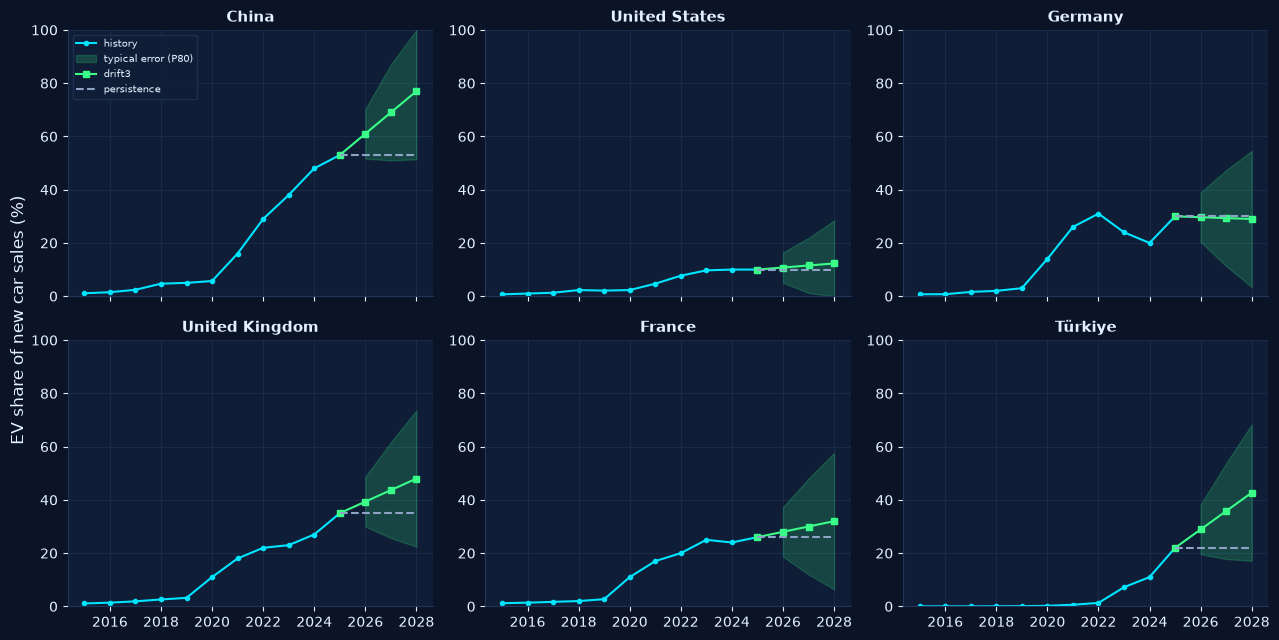

In [6]:
ORIGIN = LAST
p80 = scale.set_index(["h", "band"])["P80"]
p80_h = err.assign(abs_err=err["err"].abs()).groupby("h")["abs_err"].quantile(0.8)
rows = []
for geo in S.columns:
    s = S[geo]
    if pd.isna(s.get(ORIGIN)):
        continue
    for h in (1, 2, 3):
        f, p = forecast(s, ORIGIN, h, SELECTED), forecast(s, ORIGIN, h, "persistence")
        if np.isnan(f):
            continue
        band = pd.cut([s[ORIGIN]], [0, 5, 20, 100], labels=["<5%", "5-20%", ">=20%"], right=False).astype(str)[0]
        err80 = p80.get((h, band), p80_h[h])
        rows.append({"geo_code": geo, "geo_name": names[geo], "year": ORIGIN + h, "horizon": h, "last_share": s[ORIGIN],
                     "forecast": f, "persistence": p, "typical_error_p80": err80,
                     "range_low": max(0, f - err80), "range_high": min(100, f + err80), "near_saturation": s[ORIGIN] > 85 or f > 90})
fc = pd.DataFrame(rows)
fc.round(2).to_csv(OUT / "ev_share_forecasts_2026_2028.csv", index=False)
print(f"Forecast rows: {len(fc)} for {fc['geo_code'].nunique()} countries -> data/processed/ev_share_forecasts_2026_2028.csv")

top = volume25.merge(fc[fc["horizon"] == 3][["geo_code", "geo_name", "last_share", "forecast", "persistence", "typical_error_p80", "near_saturation"]], on="geo_code")
top = top.nlargest(10, "ev_sales_2025")
top["ev_sales_2025_m"] = top["ev_sales_2025"] / 1e6
print(f"{ORIGIN + 3} forecast for the 10 largest EV markets ({SELECTED}; persistence for reference):")
print(top[["geo_name", "ev_sales_2025_m", "last_share", "forecast", "persistence", "typical_error_p80", "near_saturation"]].round(1).to_string(index=False))

big = top["geo_code"].tolist()[:6]
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5), sharex=True)
for ax, geo in zip(axes.ravel(), big):
    h = S[geo].loc[2015:]; f = fc[fc["geo_code"] == geo].sort_values("year")
    ax.plot(h.index, h.values, color=CYAN, marker="o", ms=3, label="history")
    xs = [ORIGIN] + f["year"].tolist()
    ax.fill_between(f["year"], f["range_low"], f["range_high"], color=GREEN, alpha=0.18, label="typical error (P80)")
    ax.plot(xs, [h[ORIGIN]] + f["forecast"].tolist(), color=GREEN, marker="s", ms=4, label=SELECTED)
    ax.plot(xs, [h[ORIGIN]] + f["persistence"].tolist(), color=GREY, ls="--", label="persistence")
    ax.set_title(names[geo]); ax.set_ylim(0, 100)
axes[0, 0].legend(fontsize=7, loc="upper left"); fig.supylabel("EV share of new car sales (%)")
plt.tight_layout(); save(fig, "21_forecast_fan_charts.png"); plt.show()

### World (IEA aggregate)

World aggregate එකට country-level error ප්‍රමාණය කෙලින්ම යෙදෙන්නේ නැහැ (aggregate එකේ errors වෙනස්), ඒ නිසා මෙහි forecast line පමණයි, range එකක් නැහැ. IEA 2035 scenarios තිත් විදිහට පෙන්වා තියෙනවා, ඒවා 2028 සිට 2035 දක්වා **අපි forecast කරලා නැහැ**.

World EV share: 25% in 2025; drift3 forecast 2026: 28%, 2027: 32%, 2028: 35% | IEA 2035: STEPS 53%, CPS 46%
saved 22_world_forecast_vs_scenarios.png


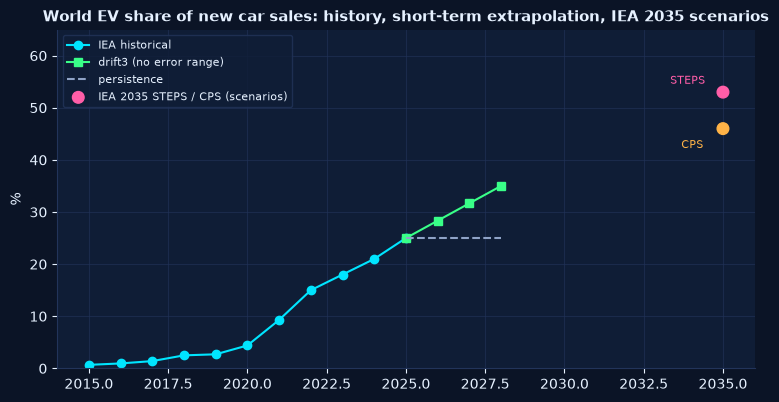

In [7]:
world = hist[hist["geo_code"] == "WLD"].set_index("year")["value"].sort_index()
wf = {h: forecast(world, ORIGIN, h, SELECTED) for h in (1, 2, 3)}
wp = {h: forecast(world, ORIGIN, h, "persistence") for h in (1, 2, 3)}
scen = shares[(shares["geo_code"] == "WLD") & (shares["scenario"] != "Historical")].set_index("scenario")["value"]
print(f"World EV share: {world.loc[ORIGIN]:.0f}% in {ORIGIN}; {SELECTED} forecast " + ", ".join(f"{ORIGIN + h}: {v:.0f}%" for h, v in wf.items())
      + f" | IEA 2035: STEPS {scen['STEPS']:.0f}%, CPS {scen['CPS']:.0f}%")

fig, ax = plt.subplots(figsize=(9, 4.4))
ax.plot(world.loc[2015:].index, world.loc[2015:].values, color=CYAN, marker="o", label="IEA historical")
ax.plot([ORIGIN] + [ORIGIN + h for h in wf], [world[ORIGIN]] + list(wf.values()), color=GREEN, marker="s", label=f"{SELECTED} (no error range)")
ax.plot([ORIGIN] + [ORIGIN + h for h in wp], [world[ORIGIN]] + list(wp.values()), color=GREY, ls="--", label="persistence")
ax.scatter([2035, 2035], [scen["STEPS"], scen["CPS"]], color=[PINK, AMBER], s=70, zorder=3, label="IEA 2035 STEPS / CPS (scenarios)")
ax.annotate("STEPS", (2035, scen["STEPS"]), xytext=(-38, 6), textcoords="offset points", fontsize=8, color=PINK)
ax.annotate("CPS", (2035, scen["CPS"]), xytext=(-30, -14), textcoords="offset points", fontsize=8, color=AMBER)
ax.set(title="World EV share of new car sales: history, short-term extrapolation, IEA 2035 scenarios", ylabel="%", ylim=(0, 65)); ax.legend(loc="upper left", fontsize=8)
save(fig, "22_world_forecast_vs_scenarios.png"); plt.show()

## 6. IEA 2035 scenarios: ඒවා ඉල්ලන වේගය vs මෑත ඉතිහාසය

2035 දක්වා extrapolate කරන්නේ නැතුව, scenario එකක් **2025 සිට 2035 දක්වා සාමාන්‍යයෙන් වසරකට කොච්චර pp ගානක වර්ධනයක්** ඉල්ලනවාද (STEPS/CPS) කියලා, **2022–2025 මෑත වේගය** එක්ක සසඳනවා. ඒක scenarios වල නිරවද්‍යතාවය පරීක්ෂාවක් නෙවෙයි, ඒවා පෙර ගමනට වඩා වේගවත්/මන්දගාමීද කියන එක පමණයි. (IEA values 2 significant figures වලට round කරලා, මෑත වේගය අවුරුදු 3ක් පමණයි.)

      geo_name  share_2022  share_2025  STEPS  CPS  recent_pp_per_yr  STEPS_pp_per_yr  CPS_pp_per_yr STEPS_vs_recent CPS_vs_recent
         China        29.0        53.0   94.0 94.0               8.0              4.1            4.1          slower        slower
Southeast Asia         1.6        18.0   58.0 36.0               5.5              4.0            1.8          slower        slower
         World        15.0        25.0   53.0 46.0               3.3              2.8            2.1          slower        slower
        Europe        21.0        28.0   85.0 89.0               2.3              5.7            6.1          faster        faster
 Latin America         1.1         7.0   25.0  9.0               2.0              1.8            0.2          slower        slower
         India         1.4         4.0   24.0  5.0               0.9              2.0            0.1          faster        slower
 United States         7.7        10.0   20.0  8.0               0.8              1

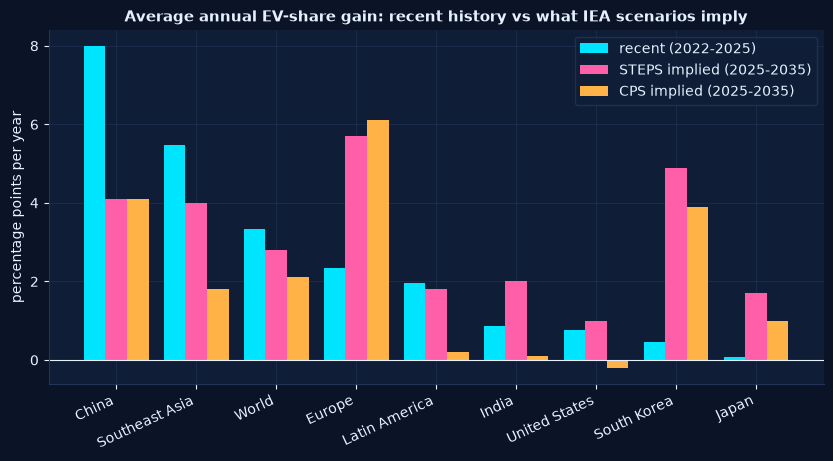

In [8]:
sc = shares[shares["scenario"] != "Historical"].pivot_table(index=["geo_code", "geo_name", "geo_type"], columns="scenario", values="value").reset_index()
h = hist.pivot(index="year", columns="geo_code", values="value")
sc["share_2025"] = sc["geo_code"].map(h.loc[2025]); sc["share_2022"] = sc["geo_code"].map(h.loc[2022])
sc["recent_pp_per_yr"] = (sc["share_2025"] - sc["share_2022"]) / 3
for s_ in ("STEPS", "CPS"):
    sc[f"{s_}_pp_per_yr"] = (sc[s_] - sc["share_2025"]) / 10
    sc[f"{s_}_vs_recent"] = np.where(sc[f"{s_}_pp_per_yr"] > sc["recent_pp_per_yr"], "faster", "slower")
sc = sc.sort_values("recent_pp_per_yr", ascending=False)
print(sc[["geo_name", "share_2022", "share_2025", "STEPS", "CPS", "recent_pp_per_yr", "STEPS_pp_per_yr", "CPS_pp_per_yr", "STEPS_vs_recent", "CPS_vs_recent"]].round(1).to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 4.6))
x = np.arange(len(sc)); w = 0.27
ax.bar(x - w, sc["recent_pp_per_yr"], w, color=CYAN, label="recent (2022-2025)")
ax.bar(x, sc["STEPS_pp_per_yr"], w, color=PINK, label="STEPS implied (2025-2035)")
ax.bar(x + w, sc["CPS_pp_per_yr"], w, color=AMBER, label="CPS implied (2025-2035)")
ax.axhline(0, color=TXT, lw=0.8); ax.set_xticks(x); ax.set_xticklabels(sc["geo_name"], rotation=25, ha="right")
ax.set(title="Average annual EV-share gain: recent history vs what IEA scenarios imply", ylabel="percentage points per year"); ax.legend()
save(fig, "23_scenario_implied_vs_recent.png"); plt.show()

## 7. Findings (data වලින්ම ගණනය කරපු)

In [9]:
sel_t, hold_t = tabs["selection"].set_index(["h", "method"]), tabs["holdout"].set_index(["h", "method"])
gain_sel = {h: 1 - sel_t.loc[(h, SELECTED), "MAE"] / sel_t.loc[(h, "persistence"), "MAE"] for h in (1, 2, 3)}
gain_hold = {h: 1 - hold_t.loc[(h, SELECTED), "MAE"] / hold_t.loc[(h, "persistence"), "MAE"] for h in (1, 2, 3)}
n_dist = int(ci["distinguishable_from_zero"].sum())
bias_p = {h: hold_t.loc[(h, "persistence"), "bias"] for h in (1, 2, 3)}; bias_s = {h: hold_t.loc[(h, SELECTED), "bias"] for h in (1, 2, 3)}
c80 = cov.loc[cov["nominal"] == 0.8].iloc[0]; c98 = cov.loc[cov["nominal"] == 0.98].iloc[0]
med_gain = (fc[fc["horizon"] == 3]["forecast"] - fc[fc["horizon"] == 3]["last_share"]).median()
more_steps = int((sc["STEPS_vs_recent"] == "faster").sum()); more_cps = int((sc["CPS_vs_recent"] == "faster").sum())
fmt = lambda d: ", ".join(f"h{h} {v:+.0%}" for h, v in d.items())
print(f"1. Method selected on 2018-2021 origins only: {SELECTED}. MAE gain vs persistence in that period: {fmt(gain_sel)}.")
print(f"2. On the 2022-2023 holdout the MAE gain vs persistence was {fmt(gain_hold)}; the bootstrap CI excludes zero for {n_dist} of 3 horizons, "
      "so the improvement is " + ("statistically supported" if n_dist == 3 else "not reliably distinguishable from persistence" if n_dist == 0 else "only partly supported") + ".")
print(f"3. Persistence under-forecasts growing markets (holdout bias {', '.join(f'h{h} {v:+.1f}' for h, v in bias_p.items())} pp) while {SELECTED} is closer to unbiased "
      f"({', '.join(f'h{h} {v:+.1f}' for h, v in bias_s.items())} pp), which matters when forecasts are added up.")
print(f"4. Empirical prediction intervals under-cover: nominal 80% -> {c80['actual_coverage']:.0%} actual, nominal 98% -> {c98['actual_coverage']:.0%} (causal backtest), "
      "so only typical error sizes (P80) are shown, not probability intervals.")
print(f"5. Median change in country EV share by {ORIGIN + 3} under {SELECTED}: {med_gain:+.1f} pp; World {world[ORIGIN]:.0f}% -> {wf[3]:.0f}% (IEA 2035: STEPS {scen['STEPS']:.0f}%, CPS {scen['CPS']:.0f}%).")
print(f"6. Of {len(sc)} geographies with IEA 2035 scenarios, STEPS implies a faster annual gain than 2022-2025 for {more_steps} and CPS for {more_cps}; the rest imply slower gains.")

1. Method selected on 2018-2021 origins only: drift3. MAE gain vs persistence in that period: h1 +26%, h2 +27%, h3 +24%.
2. On the 2022-2023 holdout the MAE gain vs persistence was h1 +0%, h2 -1%, h3 +19%; the bootstrap CI excludes zero for 0 of 3 horizons, so the improvement is not reliably distinguishable from persistence.
3. Persistence under-forecasts growing markets (holdout bias h1 -1.9, h2 -4.4, h3 -8.5 pp) while drift3 is closer to unbiased (h1 +1.6, h2 +2.6, h3 +1.6 pp), which matters when forecasts are added up.
4. Empirical prediction intervals under-cover: nominal 80% -> 58% actual, nominal 98% -> 79% (causal backtest), so only typical error sizes (P80) are shown, not probability intervals.
5. Median change in country EV share by 2028 under drift3: +7.9 pp; World 25% -> 35% (IEA 2035: STEPS 53%, CPS 46%).
6. Of 9 geographies with IEA 2035 scenarios, STEPS implies a faster annual gain than 2022-2025 for 5 and CPS for 3; the rest imply slower gains.


### සීමාවන්

- **Horizon එක අවුරුදු 3ක්.** ඊට වඩා ඈතට backtest කරලා නැහැ, ඒ නිසා 2028 ට පසු extrapolate කරන්න එපා.
- Backtest හි origins 2018–2023 පමණයි, ඒ කාලය තුළ EV වර්ධනය වේගවත් වෙමින් තිබුණා. වර්ධනය මන්දගාමී වුණොත් (saturation) ප්‍රතිඵල වෙනස් වෙන්න පුළුවන්.
- Policy වෙනස්කම් (subsidy අහෝසි වීම, tax වෙනස්කම්) මේ methods වල නැහැ.
- IEA shares round කරලා තියෙනවා (2 significant figures).
- මේ forecasts **හැම රටකටම** එකම simple method එකක්. තනි රටක් ගැන සැලසුම් කරනවා නම් ඒ රටේ policy සහ වෙළඳපොළ තත්ත්වයත් සලකන්න ඕනේ.